In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Matched-seed comparison: graph-local $R_{ZZZ}$ IQP and classical MLP

This notebook performs a direct matched-seed comparison between the improved
10-qubit graph-IQP majority policy with ten graph-local $R_{ZZZ}$ gates and the
classical MLP reported in the paper.  It does **not** rerun or alter the quantum
experiment.  Instead, it verifies and imports the completed quantum
trajectories, then trains the same classical MLP on the exact same twenty
training and evaluation seeds.

Both conditions use 500 training episodes, a trainer-side 200-step cap, the
same state normalization, REINFORCE objective, five-episode batching, Adam
configuration, entropy regularization, gradient clipping, stopping/freezing
rule, and 100 frozen held-out episodes per seed.  The primary endpoint is
normalized training-return AUC; final-50 and held-out returns are secondary.

The classical MLP has 65 trainable parameters.  The augmented quantum model
has 75 parameters (65 shared graph-IQP parameters plus ten $R_{ZZZ}$ angles).

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import hashlib
import json
import math
import platform
import sys
import time
from pathlib import Path

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import qasp
from qasp.rl.torchrl import REINFORCE

torch.set_num_threads(1)

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent

SOURCE_DIR = ROOT / "tests" / "results" / "cartpole_10q_graph_local_rzzz_uniform_ablation"
RESULTS_DIR = ROOT / "tests" / "results" / "cartpole_10q_rzzz_vs_classical_mlp_matched"
RUNS_DIR = RESULTS_DIR / "runs"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, RUNS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "lines.linewidth": 1.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

print("QASP root:", ROOT)
print("Quantum source:", SOURCE_DIR)
print("New results:", RESULTS_DIR)
print("PyTorch", torch.__version__, "| Gymnasium", gym.__version__)

QASP root: .
Quantum source: ./tests/results/cartpole_10q_graph_local_rzzz_uniform_ablation
New results: ./tests/results/cartpole_10q_rzzz_vs_classical_mlp_matched
PyTorch 2.7.0 | Gymnasium 1.0.0


## Protocol verification

The quantum source configuration is treated as the authoritative preregistered
protocol.  The assertions below prevent a comparison if its architecture,
seeds, horizon, evaluation count, or optimizer settings differ from the
classical control implemented here.

In [2]:
source_config = json.loads((SOURCE_DIR / "experiment_config.json").read_text())

SEEDS = tuple(int(seed) for seed in source_config["seeds"])
N_EPISODES = int(source_config["training_episodes"])
N_EVAL_EPISODES = int(source_config["heldout_evaluation_episodes_per_seed"])
MAX_STEPS = int(source_config["trainer_side_step_cap"])
FINAL_WINDOW = 50
SOLVED_WINDOW = 100
SOLVED_THRESHOLD = 195.0
N_JOBS = 4
MLP_HIDDEN = 9

TRAINING = source_config["training"]
assert len(SEEDS) == 20
assert N_EPISODES == 500 and N_EVAL_EPISODES == 100 and MAX_STEPS == 200
assert source_config["n_qubits"] == 10 and source_config["n_layers"] == 1
assert source_config["accepted_networkx_seed"] == 1039606416
assert source_config["rzzz_gate_count"] == 10
assert TRAINING == {
    "gamma": 0.99,
    "lr": 0.03,
    "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)",
    "batch_episodes": 5,
    "normalize_mode": "clip",
    "normalize_returns": True,
    "baseline_type": "ema",
    "baseline_momentum": 0.05,
    "entropy_coef": 0.005,
    "max_grad_norm": 1.0,
}

print("Matched seeds:", SEEDS)
print("Protocol: 500 training episodes + 100 held-out episodes; cap = 200")

Matched seeds: (61, 67, 71, 73, 79, 83, 89, 97, 101, 103, 107, 109, 113, 127, 131, 137, 139, 149, 151, 157)
Protocol: 500 training episodes + 100 held-out episodes; cap = 200


In [3]:
class MatchedClassicalPolicy(torch.nn.Module):
    # The exact 65-parameter MLP used in the paper's decoder comparison.

    def __init__(self, hidden, seed):
        super().__init__()
        torch.manual_seed(int(seed))
        np.random.seed(int(seed))
        self.network = torch.nn.Sequential(
            torch.nn.Linear(4, hidden),
            torch.nn.Tanh(),
            torch.nn.Linear(hidden, 2),
        )
        self.forward_calls = 0

    def forward(self, x):
        self.forward_calls += 1
        return self.network(x)


class TrackedREINFORCE(REINFORCE):
    def __post_init__(self):
        self.optimizer_updates = 0
        self.backward_batches = 0
        super().__post_init__()

    def _optimise_loss(self, loss):
        super()._optimise_loss(loss)
        self.optimizer_updates += 1
        self.backward_batches += 1


def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def parameter_hash(model):
    arrays = [
        value.detach().cpu().contiguous().numpy().tobytes()
        for _, value in sorted(model.named_parameters())
        if value.requires_grad
    ]
    return hashlib.sha256(b"".join(arrays)).hexdigest()


def strict_solved_episode(returns, window=SOLVED_WINDOW, threshold=SOLVED_THRESHOLD):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


def source_freeze_episode(returns):
    for episode in range(TRAINING["batch_episodes"], len(returns) + 1, TRAINING["batch_episodes"]):
        if np.mean(returns[max(0, episode - 100):episode]) >= SOLVED_THRESHOLD:
            return float(episode)
    return np.nan


probe = MatchedClassicalPolicy(MLP_HIDDEN, SEEDS[0])
assert parameter_count(probe) == 65
print("Classical MLP parameters:", parameter_count(probe))
del probe

Classical MLP parameters: 65


In [4]:
def evaluate_frozen(policy, seed):
    policy.eval()
    env = gym.make("CartPole-v1")
    returns = []
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    with torch.no_grad():
        for episode in range(N_EVAL_EPISODES):
            env_seed = 1_000_000 + 10_000 * int(seed) + episode
            action_seed = 2_000_000 + 10_000 * int(seed) + episode
            state, _ = env.reset(seed=env_seed)
            generator = torch.Generator().manual_seed(action_seed)
            total = 0.0
            for _ in range(MAX_STEPS):
                x = torch.clamp(
                    torch.as_tensor(state, dtype=torch.float32) / scale,
                    -3.0,
                    3.0,
                )
                probs = torch.softmax(policy(x), dim=-1)
                action = int(torch.multinomial(probs, 1, generator=generator).item())
                state, reward, terminated, truncated, _ = env.step(action)
                total += float(reward)
                if terminated or truncated:
                    break
            returns.append(total)
    env.close()
    return np.asarray(returns, dtype=float)


def run_one(seed):
    stem = f"classical_mlp__seed_{int(seed)}"
    npz_path = RUNS_DIR / f"{stem}.npz"
    pt_path = RUNS_DIR / f"{stem}.pt"
    json_path = RUNS_DIR / f"{stem}.json"

    if npz_path.exists() and pt_path.exists() and json_path.exists():
        arrays = np.load(npz_path)
        metadata = json.loads(json_path.read_text())
        if (
            len(arrays["training_returns"]) == N_EPISODES
            and len(arrays["evaluation_returns"]) == N_EVAL_EPISODES
            and metadata.get("seeding_protocol") == "matched_rzzz_20_seed_protocol"
        ):
            return metadata

    start = time.perf_counter()
    policy = MatchedClassicalPolicy(MLP_HIDDEN, seed)
    initial_hash = parameter_hash(policy)

    agent = TrackedREINFORCE(
        policy=policy,
        env_name="CartPole-v1",
        gamma=TRAINING["gamma"],
        lr=TRAINING["lr"],
        max_steps=MAX_STEPS,
        batch_episodes=TRAINING["batch_episodes"],
        logits=True,
        normalize_mode=TRAINING["normalize_mode"],
        normalize_returns=TRAINING["normalize_returns"],
        entropy_coef=TRAINING["entropy_coef"],
        baseline_type=TRAINING["baseline_type"],
        baseline_momentum=TRAINING["baseline_momentum"],
        max_grad_norm=TRAINING["max_grad_norm"],
    )

    torch.manual_seed(int(seed))
    np.random.seed(int(seed))
    agent.env.reset(seed=int(seed))
    agent.env.action_space.seed(int(seed))

    train_start = time.perf_counter()
    training_returns = np.asarray(
        agent.train(num_episodes=N_EPISODES, log_every=N_EPISODES), dtype=float
    )
    training_seconds = time.perf_counter() - train_start
    training_forward_calls = int(policy.forward_calls)

    eval_start = time.perf_counter()
    evaluation_returns = evaluate_frozen(policy, seed)
    evaluation_seconds = time.perf_counter() - eval_start
    evaluation_forward_calls = int(policy.forward_calls) - training_forward_calls
    agent.env.close()

    torch.save(
        {
            "policy": "classical_mlp",
            "seed": int(seed),
            "state_dict": {
                key: value.detach().cpu() for key, value in policy.state_dict().items()
            },
            "training_returns": training_returns,
            "evaluation_returns": evaluation_returns,
        },
        pt_path,
    )
    np.savez_compressed(
        npz_path,
        training_returns=training_returns,
        evaluation_returns=evaluation_returns,
    )

    metadata = {
        "run_id": stem,
        "condition": "classical MLP",
        "seed": int(seed),
        "n_parameters": parameter_count(policy),
        "initial_parameter_sha256": initial_hash,
        "execution_backend": "classical_torch",
        "seeding_protocol": "matched_rzzz_20_seed_protocol",
        "training_final_50": float(training_returns[-FINAL_WINDOW:].mean()),
        "normalized_training_auc": float(training_returns.mean() / MAX_STEPS),
        "evaluation_mean": float(evaluation_returns.mean()),
        "evaluation_std": float(evaluation_returns.std(ddof=1)),
        "strict_solved_episode": strict_solved_episode(training_returns),
        "optimizer_freeze_episode": source_freeze_episode(training_returns),
        "optimizer_updates": int(agent.optimizer_updates),
        "backward_batches": int(agent.backward_batches),
        "training_forward_calls": training_forward_calls,
        "evaluation_forward_calls": evaluation_forward_calls,
        "training_seconds": training_seconds,
        "evaluation_seconds": evaluation_seconds,
        "total_seconds": time.perf_counter() - start,
        "checkpoint_npz": str(npz_path),
        "checkpoint_pt": str(pt_path),
    }
    json_path.write_text(json.dumps(metadata, indent=2, allow_nan=True))
    print(
        "DONE", stem,
        "AUC", f"{metadata['normalized_training_auc']:.3f}",
        "final50", f"{metadata['training_final_50']:.1f}",
        "eval", f"{metadata['evaluation_mean']:.1f}",
        "seconds", f"{metadata['total_seconds']:.1f}",
        flush=True,
    )
    return metadata

## Run the matched classical control

Each seed is checkpointed independently, so this cell is safely resumable.
OMP/MKL and PyTorch intra-op parallelism are pinned to one thread per worker.

In [5]:
start_all = time.perf_counter()
mlp_metadata = joblib.Parallel(n_jobs=N_JOBS, backend="loky", verbose=10)(
    joblib.delayed(run_one)(seed) for seed in SEEDS
)
assert len(mlp_metadata) == len(SEEDS)
print("Matched MLP matrix complete in", round(time.perf_counter() - start_all, 1), "s")

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


Matched MLP matrix complete in 5.1 s


[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:    5.0s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:    5.0s
[Parallel(n_jobs=4)]: Done  16 out of  20 | elapsed:    5.1s remaining:    1.3s
[Parallel(n_jobs=4)]: Done  20 out of  20 | elapsed:    5.1s finished


## Import and verify the completed quantum trajectories

Only the `uniform_rzzz` checkpoints are imported.  The seed set and array
lengths must match exactly; no summary-only reconstruction is permitted.

In [6]:
conditions = {
    "graph-local $R_{ZZZ}$ IQP": {},
    "classical MLP": {},
}

source_run_metadata = pd.read_csv(SOURCE_DIR / "run_metadata.csv")
source_rows = source_run_metadata[source_run_metadata["condition"] == "uniform_rzzz"]
assert set(source_rows["seed"].astype(int)) == set(SEEDS)

for seed in SEEDS:
    quantum_path = SOURCE_DIR / "runs" / f"expander_10_L1__uniform_rzzz__seed_{seed}.npz"
    assert quantum_path.exists(), quantum_path
    quantum = np.load(quantum_path)
    q_train = np.asarray(quantum["training_returns"], dtype=float)
    q_eval = np.asarray(quantum["evaluation_returns"], dtype=float)
    assert len(q_train) == N_EPISODES and len(q_eval) == N_EVAL_EPISODES
    conditions["graph-local $R_{ZZZ}$ IQP"][seed] = (q_train, q_eval)

    classical = np.load(RUNS_DIR / f"classical_mlp__seed_{seed}.npz")
    c_train = np.asarray(classical["training_returns"], dtype=float)
    c_eval = np.asarray(classical["evaluation_returns"], dtype=float)
    assert len(c_train) == N_EPISODES and len(c_eval) == N_EVAL_EPISODES
    conditions["classical MLP"][seed] = (c_train, c_eval)

print("Verified seed-level trajectories for both conditions:", len(SEEDS), "seeds each")

Verified seed-level trajectories for both conditions: 20 seeds each


In [7]:
episode_rows = []
evaluation_rows = []
seed_rows = []
for condition, seed_data in conditions.items():
    for seed, (training_returns, evaluation_returns) in seed_data.items():
        episode_rows.extend(
            {"condition": condition, "seed": seed, "episode": episode + 1, "return": value}
            for episode, value in enumerate(training_returns)
        )
        evaluation_rows.extend(
            {"condition": condition, "seed": seed, "evaluation_episode": episode + 1, "return": value}
            for episode, value in enumerate(evaluation_returns)
        )
        seed_rows.append({
            "condition": condition,
            "seed": seed,
            "normalized_training_auc": float(training_returns.mean() / MAX_STEPS),
            "training_final_50": float(training_returns[-FINAL_WINDOW:].mean()),
            "heldout_evaluation_mean": float(evaluation_returns.mean()),
            "strict_solved_episode": strict_solved_episode(training_returns),
            "heldout_mean_at_least_195": bool(evaluation_returns.mean() >= SOLVED_THRESHOLD),
        })

episode_df = pd.DataFrame(episode_rows)
evaluation_df = pd.DataFrame(evaluation_rows)
seed_df = pd.DataFrame(seed_rows)
episode_df.to_csv(RESULTS_DIR / "episode_returns.csv", index=False)
evaluation_df.to_csv(RESULTS_DIR / "heldout_evaluation_returns.csv", index=False)
seed_df.to_csv(RESULTS_DIR / "seed_level_summary.csv", index=False)

summary_rows = []
for condition, frame in seed_df.groupby("condition", sort=False):
    row = {"condition": condition, "n_seeds": len(frame)}
    for metric in (
        "normalized_training_auc", "training_final_50", "heldout_evaluation_mean"
    ):
        values = frame[metric].to_numpy(float)
        row[f"mean_{metric}"] = float(values.mean())
        row[f"sem_{metric}"] = float(values.std(ddof=1) / math.sqrt(len(values)))
    row["strict_solved_seed_fraction"] = float(frame["strict_solved_episode"].notna().mean())
    row["heldout_mean_at_least_195_fraction"] = float(frame["heldout_mean_at_least_195"].mean())
    row["parameter_count"] = 75 if "R_{ZZZ}" in condition else 65
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)
summary_df

,condition,n_seeds,mean_normalized_training_auc,sem_normalized_training_auc,mean_training_final_50,sem_training_final_50,mean_heldout_evaluation_mean,sem_heldout_evaluation_mean,strict_solved_seed_fraction,heldout_mean_at_least_195_fraction,parameter_count
0,graph-local $R_{ZZZ}$ IQP,20,0.616752,0.02571,194.154,1.453036,195.3990,1.078090,0.50,0.7,75
1,classical MLP,20,0.827753,0.01071,198.454,0.544738,198.3405,0.678945,0.95,0.9,65


## Paired statistical comparisons

Differences are always **quantum minus classical**.  Intervals are percentile
bootstrap intervals over the twenty paired seeds.  The randomization test is a
two-sided paired sign-flip test.  These choices are fixed for all continuous
metrics rather than selected after viewing the result.

In [8]:
def paired_statistics(a, b, bootstrap_seed, randomization_seed, n_resamples=100_000):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    assert a.shape == b.shape == (len(SEEDS),)
    differences = a - b
    observed = float(differences.mean())

    rng = np.random.default_rng(bootstrap_seed)
    indices = rng.integers(0, len(differences), size=(n_resamples, len(differences)))
    bootstrap = differences[indices].mean(axis=1)
    ci_low, ci_high = np.percentile(bootstrap, [2.5, 97.5])

    rng = np.random.default_rng(randomization_seed)
    signs = rng.choice((-1.0, 1.0), size=(n_resamples, len(differences)))
    randomized = (signs * differences).mean(axis=1)
    p_two_sided = (1 + np.count_nonzero(np.abs(randomized) >= abs(observed))) / (n_resamples + 1)

    sd = differences.std(ddof=1)
    return {
        "n_pairs": len(differences),
        "mean_difference_quantum_minus_mlp": observed,
        "bootstrap_ci95_low": float(ci_low),
        "bootstrap_ci95_high": float(ci_high),
        "two_sided_sign_flip_p": float(p_two_sided),
        "cohens_dz": float(observed / sd) if sd > 0 else np.nan,
        "n_quantum_better": int(np.sum(differences > 0)),
        "n_ties": int(np.sum(differences == 0)),
        "n_mlp_better": int(np.sum(differences < 0)),
    }


wide = seed_df.pivot(index="seed", columns="condition")
q_label = "graph-local $R_{ZZZ}$ IQP"
c_label = "classical MLP"
paired_rows = []
for index, metric in enumerate((
    "normalized_training_auc", "training_final_50", "heldout_evaluation_mean"
)):
    row = {"metric": metric}
    row.update(paired_statistics(
        wide[metric][q_label].loc[list(SEEDS)].to_numpy(),
        wide[metric][c_label].loc[list(SEEDS)].to_numpy(),
        bootstrap_seed=20261201 + index,
        randomization_seed=20261211 + index,
    ))
    paired_rows.append(row)

paired_df = pd.DataFrame(paired_rows)
paired_df.to_csv(RESULTS_DIR / "paired_comparisons_quantum_minus_mlp.csv", index=False)
paired_df

,metric,n_pairs,mean_difference_quantum_minus_mlp,bootstrap_ci95_low,bootstrap_ci95_high,two_sided_sign_flip_p,cohens_dz,n_quantum_better,n_ties,n_mlp_better
0,normalized_training_auc,20,-0.211002,-0.260565,-0.163509,0.00002,-1.845304,0,0,20
1,training_final_50,20,-4.300000,-7.649025,-1.644975,0.00314,-0.605507,4,0,16
2,heldout_evaluation_mean,20,-2.941500,-5.375500,-0.926988,0.00914,-0.558298,5,1,14


In [9]:
def exact_mcnemar(quantum_success, mlp_success):
    quantum_success = np.asarray(quantum_success, dtype=bool)
    mlp_success = np.asarray(mlp_success, dtype=bool)
    quantum_only = int(np.sum(quantum_success & ~mlp_success))
    mlp_only = int(np.sum(~quantum_success & mlp_success))
    discordant = quantum_only + mlp_only
    if discordant == 0:
        p_value = 1.0
    else:
        lower = min(quantum_only, mlp_only)
        tail = sum(math.comb(discordant, k) for k in range(lower + 1)) / (2 ** discordant)
        p_value = min(1.0, 2.0 * tail)
    return {
        "quantum_success_mlp_failure": quantum_only,
        "quantum_failure_mlp_success": mlp_only,
        "discordant_pairs": discordant,
        "exact_two_sided_mcnemar_p": p_value,
    }


q_seed = seed_df[seed_df["condition"] == q_label].set_index("seed").loc[list(SEEDS)]
c_seed = seed_df[seed_df["condition"] == c_label].set_index("seed").loc[list(SEEDS)]
binary_rows = []
for metric, q_success, c_success in (
    (
        "strict_training_solved",
        q_seed["strict_solved_episode"].notna().to_numpy(),
        c_seed["strict_solved_episode"].notna().to_numpy(),
    ),
    (
        "heldout_mean_at_least_195",
        q_seed["heldout_mean_at_least_195"].to_numpy(bool),
        c_seed["heldout_mean_at_least_195"].to_numpy(bool),
    ),
):
    row = {
        "metric": metric,
        "n_pairs": len(SEEDS),
        "quantum_success_fraction": float(np.mean(q_success)),
        "mlp_success_fraction": float(np.mean(c_success)),
    }
    row.update(exact_mcnemar(q_success, c_success))
    binary_rows.append(row)

binary_df = pd.DataFrame(binary_rows)
binary_df.to_csv(RESULTS_DIR / "paired_binary_comparisons.csv", index=False)
binary_df

,metric,n_pairs,quantum_success_fraction,mlp_success_fraction,quantum_success_mlp_failure,quantum_failure_mlp_success,discordant_pairs,exact_two_sided_mcnemar_p
0,strict_training_solved,20,0.5,0.95,0,9,9,0.003906
1,heldout_mean_at_least_195,20,0.7,0.90,1,5,6,0.218750


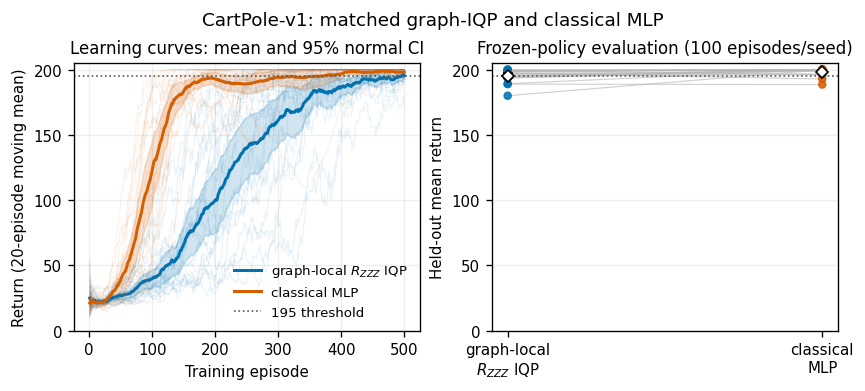

./tests/results/cartpole_10q_rzzz_vs_classical_mlp_matched/figures/cartpole_10q_rzzz_vs_classical_mlp_matched.png
./tests/results/cartpole_10q_rzzz_vs_classical_mlp_matched/figures/cartpole_10q_rzzz_vs_classical_mlp_matched.pdf


In [10]:
colors = {
    q_label: "#0072B2",
    c_label: "#D55E00",
}

fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.15), constrained_layout=True)

ax = axes[0]
for condition in (q_label, c_label):
    matrix = np.vstack([
        conditions[condition][seed][0] for seed in SEEDS
    ])
    smooth = np.vstack([
        pd.Series(row).rolling(20, min_periods=1).mean().to_numpy()
        for row in matrix
    ])
    for row in smooth:
        ax.plot(np.arange(1, N_EPISODES + 1), row, color=colors[condition], alpha=0.09, lw=0.6)
    mean = smooth.mean(axis=0)
    sem = smooth.std(axis=0, ddof=1) / math.sqrt(len(SEEDS))
    low = np.clip(mean - 1.96 * sem, 0, MAX_STEPS)
    high = np.clip(mean + 1.96 * sem, 0, MAX_STEPS)
    ax.fill_between(np.arange(1, N_EPISODES + 1), low, high, color=colors[condition], alpha=0.18)
    ax.plot(np.arange(1, N_EPISODES + 1), mean, color=colors[condition], label=condition)
ax.axhline(195, color="0.35", ls=":", lw=1.0, label="195 threshold")
ax.set(xlabel="Training episode", ylabel="Return (20-episode moving mean)", ylim=(0, 205))
ax.set_title("Learning curves: mean and 95% normal CI")
ax.legend(frameon=False, loc="lower right")
ax.grid(alpha=0.2)

ax = axes[1]
heldout = seed_df.pivot(index="seed", columns="condition", values="heldout_evaluation_mean").loc[list(SEEDS)]
x = np.array([0.0, 1.0])
for seed in SEEDS:
    values = heldout.loc[seed, [q_label, c_label]].to_numpy(float)
    ax.plot(x, values, color="0.72", lw=0.7, alpha=0.65, zorder=1)
    ax.scatter(x, values, c=[colors[q_label], colors[c_label]], s=17, alpha=0.85, zorder=2)
means = heldout[[q_label, c_label]].mean().to_numpy(float)
sems = heldout[[q_label, c_label]].sem().to_numpy(float)
ax.errorbar(x, means, yerr=1.96 * sems, fmt="D", color="black", mfc="white", ms=5, capsize=3, zorder=3)
ax.axhline(195, color="0.35", ls=":", lw=1.0)
ax.set_xticks(x, ["graph-local\n$R_{ZZZ}$ IQP", "classical\nMLP"])
ax.set(ylabel="Held-out mean return", ylim=(0, 205))
ax.set_title("Frozen-policy evaluation (100 episodes/seed)")
ax.grid(axis="y", alpha=0.2)

fig.suptitle("CartPole-v1: matched graph-IQP and classical MLP", fontsize=11)
png_path = FIGURES_DIR / "cartpole_10q_rzzz_vs_classical_mlp_matched.png"
pdf_path = FIGURES_DIR / "cartpole_10q_rzzz_vs_classical_mlp_matched.pdf"
fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()
print(png_path)
print(pdf_path)

In [11]:
config = {
    "environment_label": "CartPole-v1 with trainer-side 200-step cap",
    "gymnasium_environment_id": "CartPole-v1",
    "training_episodes": N_EPISODES,
    "heldout_evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "seeds": list(SEEDS),
    "training": TRAINING,
    "classical_mlp_hidden_units": MLP_HIDDEN,
    "classical_mlp_parameter_count": 65,
    "graph_local_rzzz_parameter_count": 75,
    "quantum_source_directory": str(SOURCE_DIR),
    "quantum_condition_imported": "uniform_rzzz",
    "primary_endpoint": "normalized training-return AUC over 500 episodes",
    "paired_difference_direction": "graph-local RZZZ IQP minus classical MLP",
    "bootstrap_resamples": 100_000,
    "randomization_resamples": 100_000,
}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))

software = {
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "gymnasium": gym.__version__,
    "qasp_file": str(Path(qasp.__file__).resolve()),
}
(RESULTS_DIR / "software_metadata.json").write_text(json.dumps(software, indent=2))

run_metadata_df = pd.DataFrame(mlp_metadata)
run_metadata_df.to_csv(RESULTS_DIR / "classical_mlp_run_metadata.csv", index=False)

manifest = {
    "notebook": str(ROOT / "tests" / "cartpole_10q_rzzz_vs_classical_mlp_matched.ipynb"),
    "results_directory": str(RESULTS_DIR),
    "files": sorted(str(path.relative_to(RESULTS_DIR)) for path in RESULTS_DIR.rglob("*") if path.is_file()),
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Final summaries")
display(summary_df)
display(paired_df)
display(binary_df)
print("All artifacts saved to", RESULTS_DIR)

Final summaries


,condition,n_seeds,mean_normalized_training_auc,sem_normalized_training_auc,mean_training_final_50,sem_training_final_50,mean_heldout_evaluation_mean,sem_heldout_evaluation_mean,strict_solved_seed_fraction,heldout_mean_at_least_195_fraction,parameter_count
0,graph-local $R_{ZZZ}$ IQP,20,0.616752,0.02571,194.154,1.453036,195.3990,1.078090,0.50,0.7,75
1,classical MLP,20,0.827753,0.01071,198.454,0.544738,198.3405,0.678945,0.95,0.9,65


,metric,n_pairs,mean_difference_quantum_minus_mlp,bootstrap_ci95_low,bootstrap_ci95_high,two_sided_sign_flip_p,cohens_dz,n_quantum_better,n_ties,n_mlp_better
0,normalized_training_auc,20,-0.211002,-0.260565,-0.163509,0.00002,-1.845304,0,0,20
1,training_final_50,20,-4.300000,-7.649025,-1.644975,0.00314,-0.605507,4,0,16
2,heldout_evaluation_mean,20,-2.941500,-5.375500,-0.926988,0.00914,-0.558298,5,1,14


,metric,n_pairs,quantum_success_fraction,mlp_success_fraction,quantum_success_mlp_failure,quantum_failure_mlp_success,discordant_pairs,exact_two_sided_mcnemar_p
0,strict_training_solved,20,0.5,0.95,0,9,9,0.003906
1,heldout_mean_at_least_195,20,0.7,0.90,1,5,6,0.218750


All artifacts saved to ./tests/results/cartpole_10q_rzzz_vs_classical_mlp_matched


## Interpretation rule

The augmented quantum model is considered to outperform the MLP on a metric
only if the paired quantum-minus-MLP confidence interval lies wholly above
zero.  A result against the original quantum baseline does not imply an
advantage over this classical control.